In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
from google.colab import files
uploaded = files.upload()

Saving cleaned_enron_spam_data.zip to cleaned_enron_spam_data (1).zip


In [12]:
import zipfile
import os

with zipfile.ZipFile('cleaned_enron_spam_data.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

os.listdir('/content/')

['.config',
 'cleaned_enron_spam_data.zip',
 'cleaned_enron_spam_data.csv',
 'cleaned_enron_spam_data (1).zip',
 'sample_data']

In [13]:
df = pd.read_csv('/content/cleaned_enron_spam_data.csv')

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

df.head()

Dataset Shape: (33716, 7)

Column Names:
['Message ID', 'Subject', 'Message', 'Spam/Ham', 'Date', 'Message_Length', 'Message_Length_Scaled']


,Message ID,Subject,Message,Spam/Ham,Date,Message_Length,Message_Length_Scaled
0,0,christmas tree farm pictures,NaN,0,1999-12-10,0,-0.343257
1,1,"vastar resources , inc .","gary , production from the high island larger ...",0,1999-12-13,4282,0.656405
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,0,1999-12-14,38,-0.334385
3,3,re : issue,fyi - see note below - already done .\nstella\...,0,1999-12-14,1171,-0.069879
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,0,1999-12-14,1124,-0.080851


In [14]:
print(df.columns.tolist())

['Message ID', 'Subject', 'Message', 'Spam/Ham', 'Date', 'Message_Length', 'Message_Length_Scaled']


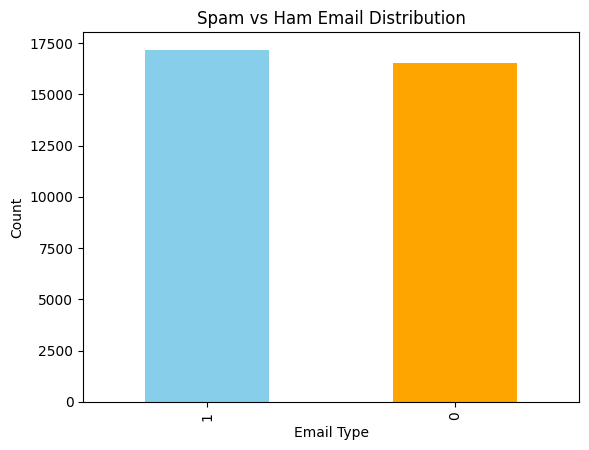

In [15]:
df['Spam/Ham'].value_counts().plot(
    kind='bar',
    color=['skyblue', 'orange']
)

plt.title('Spam vs Ham Email Distribution')
plt.xlabel('Email Type')
plt.ylabel('Count')
plt.show()

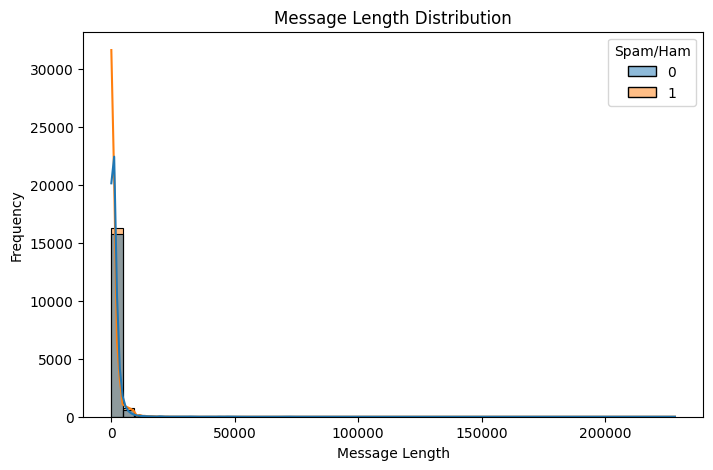

In [16]:
df['Message_Length'] = df['Message'].astype(str).apply(len)

plt.figure(figsize=(8,5))
sns.histplot(
    data=df,
    x='Message_Length',
    hue='Spam/Ham',
    bins=50,
    kde=True
)

plt.title('Message Length Distribution')
plt.xlabel('Message Length')
plt.ylabel('Frequency')
plt.show()

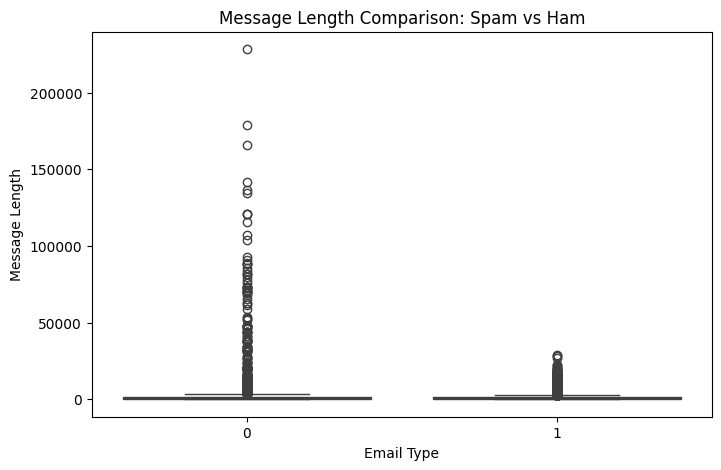

In [17]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Spam/Ham',
    y='Message_Length'
)

plt.title('Message Length Comparison: Spam vs Ham')
plt.xlabel('Email Type')
plt.ylabel('Message Length')
plt.show()

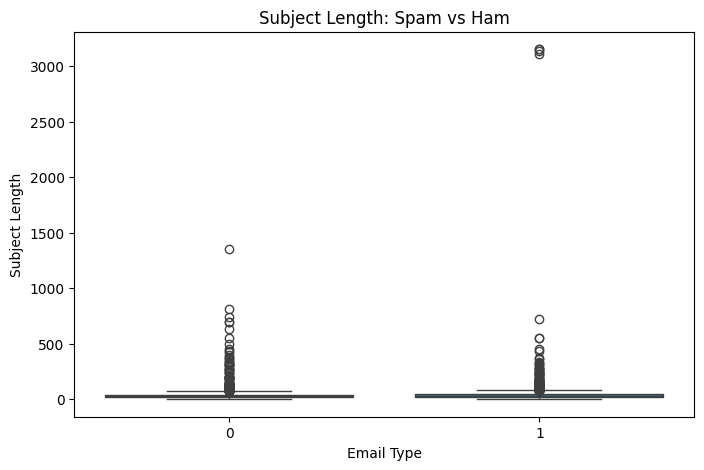

In [18]:
df['Subject_Length'] = df['Subject'].astype(str).apply(len)

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='Spam/Ham',
    y='Subject_Length'
)

plt.title('Subject Length: Spam vs Ham')
plt.xlabel('Email Type')
plt.ylabel('Subject Length')
plt.show()

In [19]:
email_counts = df['Spam/Ham'].value_counts()

email_percentage = df['Spam/Ham'].value_counts(normalize=True) * 100

print("Email Counts:")
print(email_counts)

print("\nEmail Percentage:")
print(email_percentage.round(2))

Email Counts:
Spam/Ham
1    17171
0    16545
Name: count, dtype: int64

Email Percentage:
Spam/Ham
1    50.93
0    49.07
Name: proportion, dtype: float64


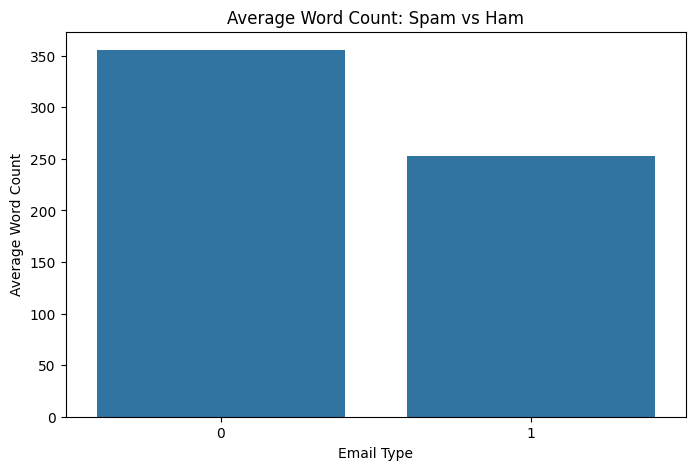

In [20]:
df['Word_Count'] = df['Message'].astype(str).apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x='Spam/Ham',
    y='Word_Count',
    errorbar=None
)

plt.title('Average Word Count: Spam vs Ham')
plt.xlabel('Email Type')
plt.ylabel('Average Word Count')
plt.show()

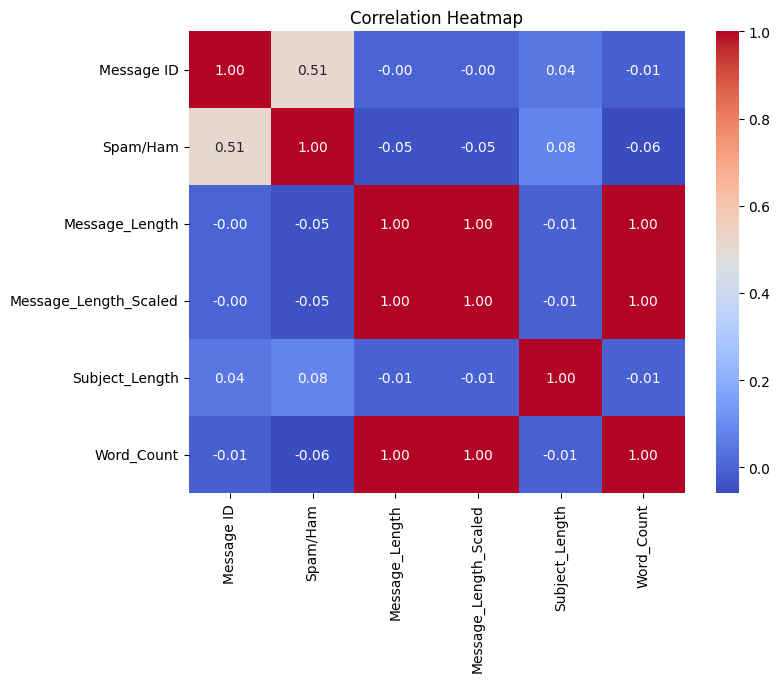

In [21]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(8,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

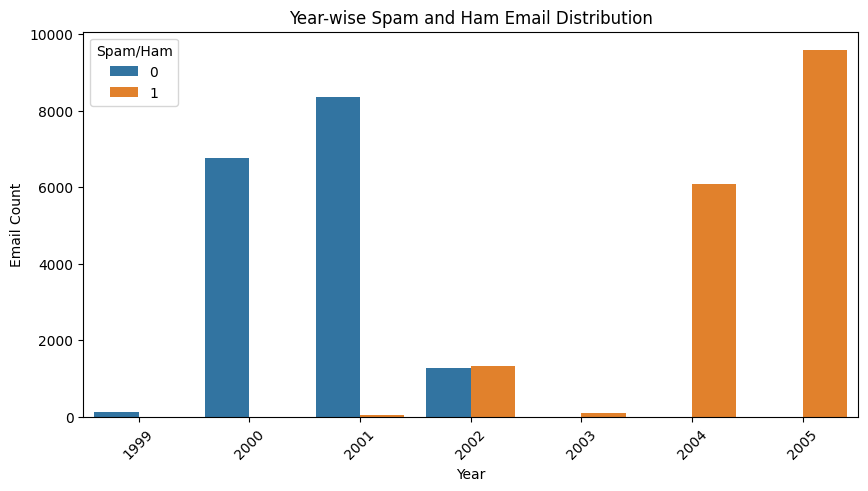

In [22]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

df['Year'] = df['Date'].dt.year

plt.figure(figsize=(10,5))

sns.countplot(
    data=df,
    x='Year',
    hue='Spam/Ham'
)

plt.title('Year-wise Spam and Ham Email Distribution')
plt.xlabel('Year')
plt.ylabel('Email Count')
plt.xticks(rotation=45)
plt.show()

In [23]:
print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("----------------------------------")

print("Total Emails:", len(df))

print("\nSpam and Ham Counts:")
print(df['Spam/Ham'].value_counts())

print("\nAverage Message Length:")
print(df.groupby('Spam/Ham')['Message_Length'].mean().round(2))

print("\nAverage Subject Length:")
print(df.groupby('Spam/Ham')['Subject_Length'].mean().round(2))

print("\nAverage Word Count:")
print(df.groupby('Spam/Ham')['Word_Count'].mean().round(2))

EXPLORATORY DATA ANALYSIS SUMMARY
----------------------------------
Total Emails: 33716

Spam and Ham Counts:
Spam/Ham
1    17171
0    16545
Name: count, dtype: int64

Average Message Length:
Spam/Ham
0    1676.30
1    1271.92
Name: Message_Length, dtype: float64

Average Subject Length:
Spam/Ham
0    31.15
1    37.92
Name: Subject_Length, dtype: float64

Average Word Count:
Spam/Ham
0    355.47
1    253.24
Name: Word_Count, dtype: float64
